# Practical applications

Worked examples of divinity on real and simulated problems. Each section fits a model on history, forecasts a period we already know the answer to, and then checks the forecast against what actually happened. That way you can judge whether to trust it, not just look at a chart.

Real data (CO₂, sea temperature, sunspots, US macroeconomics) ships with statsmodels, so nothing is downloaded. Business data (sales, web traffic, revenue, a sensor) is simulated, because real company figures are not public. Every simulated series is reproducible from its seed.

| Section | Data |
|---|---|
| 1. Retail demand planning | simulated daily sales |
| 2. Capacity planning | simulated hourly web traffic |
| 3. Revenue budgeting | simulated monthly revenue |
| 4. Environmental monitoring | real weekly CO₂ at Mauna Loa |
| 5. Seasonal climate outlook | real monthly Pacific sea temperature |
| 6. Discovering cycles | real yearly sunspot counts |
| 7. Anomaly detection | simulated hourly sensor with a fault |
| 8. Financial risk ranges | real US Treasury bill rate |
| 9. Knowing the limits | real US GDP through 2008 |

In [1]:
import warnings

import numpy as np
import pandas as pd

import divinity as dv
from divinity import datasets

warnings.filterwarnings("ignore")
%matplotlib inline


def inside(actual, forecast):
    """Share of actual values that fell inside the prediction interval, matched by date."""
    a = actual.reindex(forecast.index).dropna()
    f = forecast.loc[a.index]
    return np.mean((a >= f["lower"]) & (a <= f["upper"]))

## 1. Retail demand planning

**Question.** How much should the shop stock each day so that it rarely runs out, without tying up money in excess stock?

**Approach.** Forecast 90 days of daily sales. The upper end of a 90% interval is the 95th percentile of likely demand, so ordering that much should leave the shop short on about 1 day in 20.

In [2]:
sales = datasets.retail_sales()
history, actual = sales[:-90], sales[-90:]

model = dv.Forecaster().fit(history)
print(model.summary())

plan = model.predict(90, interval=0.9)
plan["order_quantity"] = plan["upper"].round()
plan.head(7)

Divinity forecaster
  observations   1095
  frequency      D
  log scale      no
  trend          linear
  seasonality    365.25 (2 harmonics), 7 (3 harmonics)
  residuals      ARIMA(0, 0, 0)


,forecast,lower,upper,order_quantity
2024-12-31,174.876355,165.106626,184.646084,185.0
2025-01-01,176.595930,166.821540,186.370321,186.0
2025-01-02,178.032812,168.269210,187.796413,188.0
2025-01-03,190.616762,180.848745,200.384779,200.0
2025-01-04,195.483968,185.713492,205.254445,205.0
2025-01-05,157.809180,148.047477,167.570882,168.0
2025-01-06,171.325919,161.563847,181.087990,181.0


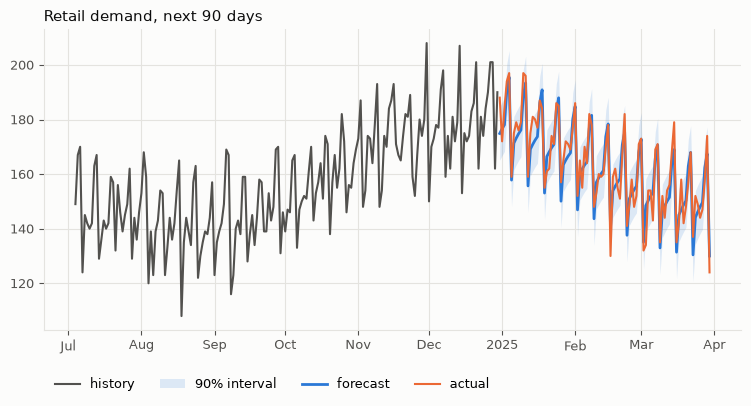

In [3]:
model.plot(plan, actual=actual, history=180, title="Retail demand, next 90 days");

Did the plan work? Count the days demand beat the order, and compare stock held with simply ordering the forecast.

In [4]:
short_days = int((actual > plan["order_quantity"]).sum())
spare = (plan["order_quantity"] - actual).clip(lower=0).mean()
print(f"Days short of stock: {short_days} of 90 (target about {0.05 * 90:.0f})")
print(f"Average spare units a day: {spare:.1f}")
print(f"Days short if we had ordered the point forecast: {int((actual > plan['forecast'].round()).sum())} of 90")

Days short of stock: 2 of 90 (target about 4)
Average spare units a day: 8.8
Days short if we had ordered the point forecast: 53 of 90


Ordering the point forecast runs out on more than half the days, because the point forecast is the middle of the range. The interval turns a forecast into a stocking decision with a known risk. Pick the interval to match the cost of running out against the cost of spare stock.

## 2. Capacity planning

**Question.** How many visits an hour must the website handle next week?

**Approach.** Hourly data gives daily (24 hour) and weekly (168 hour) cycles automatically. The upper end of a 98% interval is the 99th percentile for each hour.

Divinity forecaster
  observations   1512
  frequency      h
  log scale      no
  trend          linear
  seasonality    24 (3 harmonics), 168 (2 harmonics)
  residuals      ARIMA(2, 0, 0)


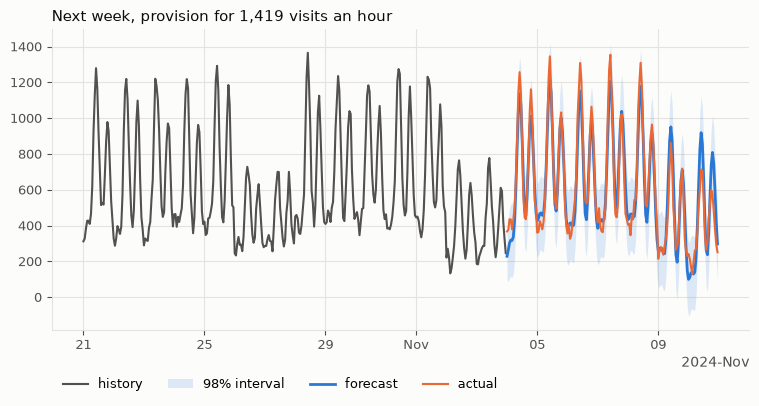

In [5]:
visits = datasets.web_traffic()
history, actual = visits[: -7 * 24], visits[-7 * 24 :]

model = dv.Forecaster().fit(history)
print(model.summary())

week = model.predict(7 * 24, interval=0.98)
peak = week["upper"].max()
model.plot(week, actual=actual, history=14 * 24, title=f"Next week, provision for {peak:,.0f} visits an hour");

In [6]:
daily = pd.DataFrame({
    "forecast peak": week["forecast"].resample("D").max().round(),
    "provision (99th percentile)": week["upper"].resample("D").max().round(),
    "actual peak": actual.resample("D").max(),
})
daily

,forecast peak,provision (99th percentile),actual peak
2024-11-04,1137.0,1342.0,1257.0
2024-11-05,1214.0,1419.0,1345.0
2024-11-06,1152.0,1357.0,1308.0
2024-11-07,1206.0,1411.0,1354.0
2024-11-08,1177.0,1382.0,1309.0
2024-11-09,951.0,1156.0,861.0
2024-11-10,919.0,1124.0,713.0


In [7]:
print(f"Hours where traffic beat that hour's provision: {int((actual > week['upper']).sum())} of {len(actual)}")
print(f"Busiest actual hour {actual.max():,.0f} against a weekly provision of {peak:,.0f}")

Hours where traffic beat that hour's provision: 1 of 168
Busiest actual hour 1,354 against a weekly provision of 1,419


The lower bound dips below zero overnight. Visits cannot be negative, but the model does not know that. It does not matter here because capacity planning only uses the upper end.

## 3. Revenue budgeting

**Question.** What monthly revenue should next year's budget assume?

**Approach.** The business grows about 12% a year and its seasonal swing grows with it, so the seasonal effect is a percentage, not a fixed amount. Fitting with `log=True` models exactly that.

Divinity forecaster
  observations   96
  frequency      MS
  log scale      yes
  trend          linear
  seasonality    12 (2 harmonics)
  residuals      ARIMA(0, 0, 0)


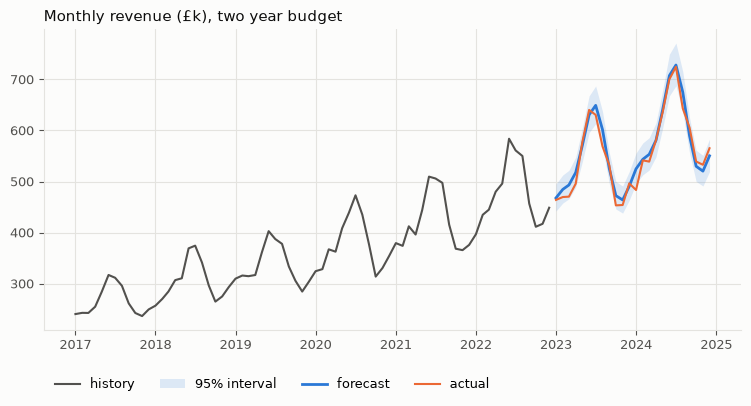

In [8]:
revenue = datasets.monthly_revenue()
history, actual = revenue[:-24], revenue[-24:]

model = dv.Forecaster(log=True).fit(history)
print(model.summary())
budget = model.predict(24)
model.plot(budget, actual=actual, history=72, title="Monthly revenue (£k), two year budget");

In [9]:
check = budget.assign(actual=actual)
check["error %"] = (100 * (check["actual"] / check["forecast"] - 1)).round(1)
check.round(1).head(12)

,forecast,lower,upper,actual,error %
2023-01-01,467.9,442.2,495.1,464.0,-0.8
2023-02-01,484.6,457.8,512.8,469.6,-3.1
2023-03-01,493.2,466.1,521.9,470.4,-4.6
2023-04-01,517.7,489.1,547.9,495.8,-4.2
2023-05-01,570.4,538.7,604.0,576.9,1.1
2023-06-01,630.6,595.6,667.6,640.2,1.5
2023-07-01,649.2,613.3,687.1,630.5,-2.9
2023-08-01,601.8,568.2,637.4,569.0,-5.5
2023-09-01,525.5,496.1,556.6,532.0,1.2
2023-10-01,472.3,446.2,500.0,453.3,-4.0


In [10]:
year1 = budget.iloc[:12]
print(f"Year one budget (sum of monthly forecasts): £{year1['forecast'].sum():,.0f}k")
print(f"Year one actual: £{actual.iloc[:12].sum():,.0f}k")
print(f"Months inside the 95% interval: {inside(actual, budget):.0%}")

Year one budget (sum of monthly forecasts): £6,368k
Year one actual: £6,252k
Months inside the 95% interval: 96%


**Careful with totals.** Adding up the monthly forecasts gives a sensible annual figure. Adding up the monthly *bounds* does not give an annual interval, because months are not all high or all low together. That would overstate the range. To get an annual range, fit the model on annual totals, or simulate.

## 4. Environmental monitoring

**Question.** Where are atmospheric CO₂ concentrations heading over the next two years?

**Data.** Real weekly readings from Mauna Loa. 59 weeks are missing where instruments were down. They are left as gaps, with no filling in required.

2284 weeks, 59 missing


Divinity forecaster
  observations   626
  frequency      W-SAT
  log scale      no
  trend          linear
  seasonality    52.1786 (2 harmonics)
  residuals      ARIMA(0, 1, 2)


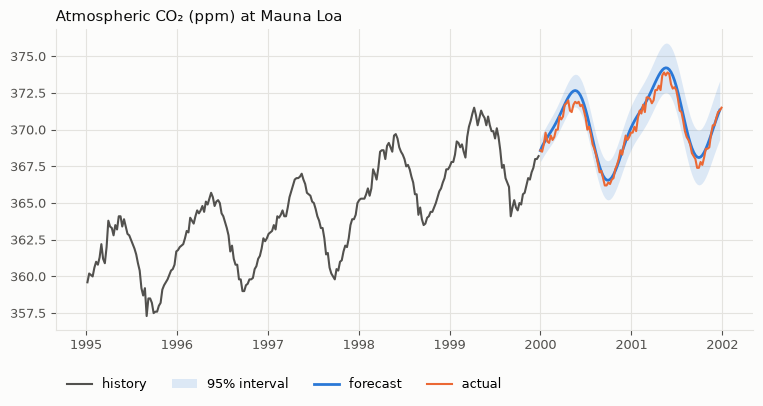

In [11]:
co2 = datasets.co2()
print(f"{len(co2)} weeks, {int(co2.isna().sum())} missing")

model = dv.Forecaster().fit(co2["1988":"1999"])
print(model.summary())
outlook = model.predict(104)
model.plot(outlook, actual=co2["2000":], history=260, title="Atmospheric CO₂ (ppm) at Mauna Loa");

In [12]:
truth = co2.interpolate().reindex(outlook.index)
print(f"Weeks inside the 95% interval: {inside(truth, outlook):.0%}")
print(f"Error after two years: {outlook['forecast'].iloc[-1] - truth.iloc[-1]:+.2f} ppm")

Weeks inside the 95% interval: 98%
Error after two years: +0.03 ppm


Weekly CO₂ behaves like a random walk around its trend (weather moves readings for weeks at a time), so the model differences the series. It keeps the upward drift because a drift matters more the further ahead you look.

Over much longer periods CO₂ growth accelerates, which a straight line trend cannot follow. For forecasts many years out, fit a shorter recent window as here, or model the growth rate.

## 5. Seasonal climate outlook

**Question.** What will Pacific sea surface temperatures look like over the next five years?

**Data.** Real monthly temperatures in the El Niño region since 1950.

Divinity forecaster
  observations   672
  frequency      MS
  log scale      no
  trend          none
  seasonality    12 (3 harmonics)
  residuals      ARIMA(2, 0, 0)


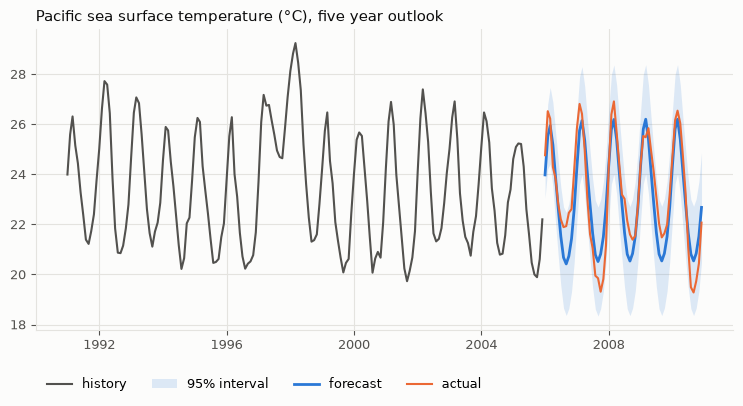

In [13]:
sst = datasets.elnino()
model = dv.Forecaster().fit(sst[:"2005"])
print(model.summary())
outlook = model.predict(60)
model.plot(outlook, actual=sst["2006":], history=180, title="Pacific sea surface temperature (°C), five year outlook");

In [14]:
print(f"Months inside the 95% interval: {inside(sst['2006':], outlook):.0%}")
seasonal = sst[:"2005"].groupby(sst[:"2005"].index.month).mean()
print("Average temperature by calendar month:")
print(seasonal.round(1).to_string())

Months inside the 95% interval: 100%
Average temperature by calendar month:
1     24.4
2     25.8
3     26.2
4     25.4
5     24.2
6     22.8
7     21.7
8     20.8
9     20.6
10    20.9
11    21.5
12    22.7


The seasonal cycle is reliable and the model captures it. El Niño and La Niña episodes are not predictable from temperature history alone. After the first few months the forecast settles to the seasonal average, and the interval widens to cover a typical El Niño or La Niña year.

## 6. Discovering cycles

**Question.** Is there a regular cycle in a series, and how long is it?

**Data.** Real yearly sunspot counts since 1700. The model is given no hint about the solar cycle.

In [15]:
sun = datasets.sunspots()
model = dv.Forecaster().fit(sun[:"1979"])
print(model.summary())
print("Candidate periods found in the periodogram:", [round(p, 1) for p in model.candidate_periods_["detected"]])

Divinity forecaster
  observations   280
  frequency      YS-JAN
  log scale      no
  trend          none
  seasonality    11.0345 (1 harmonic, detected), 10 (1 harmonic, detected)
  residuals      ARIMA(2, 1, 1)
Candidate periods found in the periodogram: [11.0, 10.0, 97.4]


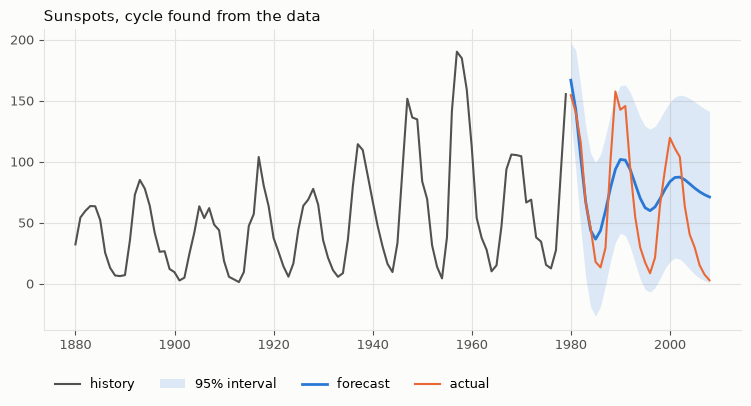

In [16]:
forecast = model.predict(29)
model.plot(forecast, actual=sun["1980":], history=100, title="Sunspots, cycle found from the data");

The model finds periods of about 11 and 10 years. Together they describe the solar cycle, whose length varies between roughly 9 and 14 years. Because it varies, the forecast drifts out of phase after a cycle or two and the interval widens.

The lower bound goes below zero. Sunspot counts cannot be negative, so clip the bound at zero for presentation.

## 7. Anomaly detection

**Question.** Has a sensor started misbehaving?

**Approach.** Forecast what the sensor should read, then flag readings outside a 99% interval. That adapts the threshold to the time of day, which a fixed threshold cannot do.

**Data.** A simulated hourly temperature sensor with a daily cycle and a few dropped readings. On its last day the sensor develops a fault and drifts upwards for six hours.

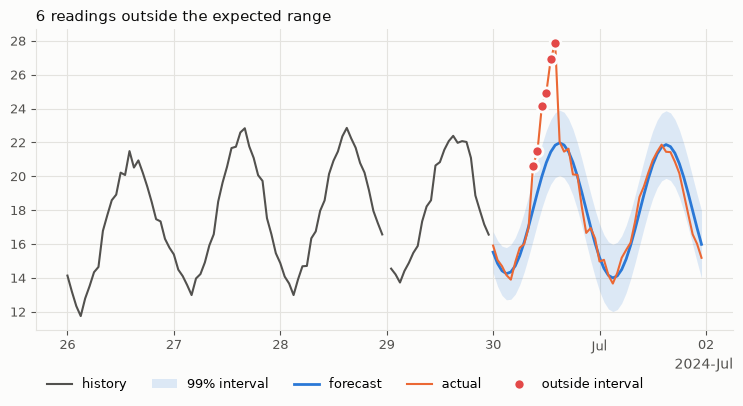

In [17]:
readings = datasets.sensor_readings()
history, recent = readings[:-48], readings[-48:]

model = dv.Forecaster(interval=0.99).fit(history)
expected = model.predict(48)
alarms = recent[(recent < expected["lower"]) | (recent > expected["upper"])]

model.plot(expected, actual=recent, highlight=alarms, history=96, title=f"{len(alarms)} readings outside the expected range");

In [18]:
report = pd.DataFrame({
    "reading": alarms,
    "expected": expected.loc[alarms.index, "forecast"].round(2),
    "upper limit": expected.loc[alarms.index, "upper"].round(2),
})
report["excess"] = (report["reading"] - report["upper limit"]).round(2)
print("Flagged readings match the injected fault exactly:", list(alarms.index) == readings.attrs["fault"])
report

Flagged readings match the injected fault exactly: True


,reading,expected,upper limit,excess
2024-06-30 09:00:00,20.62,18.04,19.87,0.75
2024-06-30 10:00:00,21.47,19.05,20.90,0.57
2024-06-30 11:00:00,24.17,20.00,21.87,2.30
2024-06-30 12:00:00,24.95,20.81,22.70,2.25
2024-06-30 13:00:00,26.92,21.44,23.35,3.57
2024-06-30 14:00:00,27.87,21.84,23.76,4.11


Why not a fixed threshold? Normal afternoon readings typically peak around 22 °C and have reached 24 °C. The first faulty reading is 20.6 °C, at 9 am. A threshold high enough to stay quiet every afternoon would miss the start of the fault. One low enough to catch it would fire every afternoon. The forecast knows what each hour should look like.

In a live system you would refit periodically (say daily) and compare each new reading with the latest forecast.

## 8. Financial risk ranges

**Question.** Where might short term interest rates be in a few years?

**Data.** Real 3 month US Treasury bill rate, quarterly.

Divinity forecaster
  observations   184
  frequency      QS-JAN
  log scale      no
  trend          none
  seasonality    none
  residuals      ARIMA(2, 1, 1)


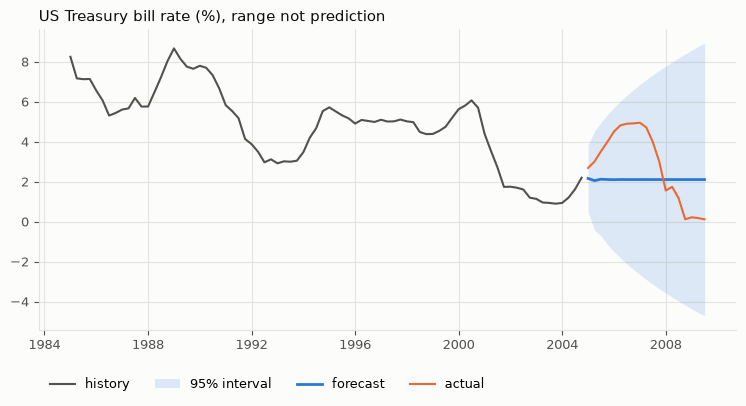

In [19]:
rate = datasets.us_macro("tbilrate")
model = dv.Forecaster().fit(rate[:"2004"])
print(model.summary())
forecast = model.predict(19)
model.plot(forecast, actual=rate["2005":], history=80, title="US Treasury bill rate (%), range not prediction");

In [20]:
naive = rate[:"2004"].iloc[-1]
actual = rate["2005":]
print(f"Quarters inside the 95% interval: {inside(actual, forecast):.0%}")
print(f"Forecast error (RMSE): {np.sqrt(np.mean((forecast['forecast'] - actual) ** 2)):.2f} points")
print(f"Error of just repeating the last rate: {np.sqrt(np.mean((naive - actual) ** 2)):.2f} points")

Quarters inside the 95% interval: 100%
Forecast error (RMSE): 1.94 points
Error of just repeating the last rate: 1.90 points


The model finds no trend or cycle and differences the series, which amounts to treating rates as a random walk. Its point forecast is no better than "rates stay where they are", and nothing built on the series alone could do better. The value is in the range. It is wide, it widens with time, and it contained what actually happened, including the 2008 cut to near zero.

Its lower end goes well below zero, which real rates almost never do. Read the lower bound as "towards zero".

## 9. Knowing the limits

Every forecast built from a series' own history assumes that the future behaves like the past. US real GDP fitted up to 2006 shows what happens when it does not.

Divinity forecaster
  observations   192
  frequency      QS-JAN
  log scale      yes
  trend          linear
  seasonality    none
  residuals      ARIMA(1, 1, 0)


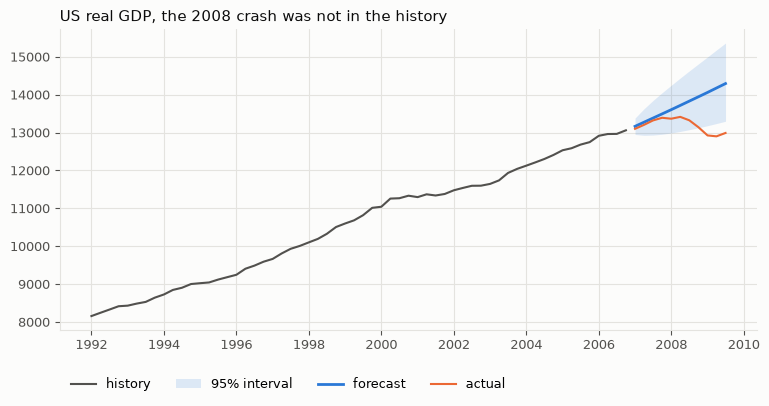

In [21]:
gdp = datasets.us_macro("realgdp")
model = dv.Forecaster(log=True).fit(gdp[:"2006"])
print(model.summary())
forecast = model.predict(11)
model.plot(forecast, actual=gdp["2007":], history=60, title="US real GDP, the 2008 crash was not in the history");

In [22]:
check = forecast.assign(actual=gdp["2007":])
check["outside interval"] = (check["actual"] < check["lower"]) | (check["actual"] > check["upper"])
check.round(0)

,forecast,lower,upper,actual,outside interval
2007-01-01,13166.0,12951.0,13384.0,13100.0,False
2007-04-01,13274.0,12929.0,13628.0,13204.0,False
2007-07-01,13383.0,12935.0,13847.0,13321.0,False
2007-10-01,13494.0,12957.0,14053.0,13391.0,False
2008-01-01,13605.0,12990.0,14250.0,13367.0,False
2008-04-01,13718.0,13031.0,14441.0,13415.0,False
2008-07-01,13831.0,13077.0,14629.0,13325.0,False
2008-10-01,13946.0,13128.0,14814.0,13142.0,False
2009-01-01,14061.0,13182.0,14998.0,12925.0,True
2009-04-01,14177.0,13240.0,15181.0,12902.0,True


The forecast continues the long run growth trend, and through 2007 that was right. The financial crisis was not in GDP's history, so no forecast built from that history could have seen it coming, and the last quarters fall below the interval.

Use forecasts like these for planning under normal conditions. Pair them with judgement or scenario planning for shocks, and refit as soon as new data shows a change.